In [55]:
# 그래프관련 import 
import matplotlib.pyplot as plt
import matplotlib
matplotlib.rcParams['font.family'] = 'Malgun Gothic'
matplotlib.rcParams['axes.unicode_minus']=False

# 프로그램 
import pandas as pd
import numpy as np
from sklearn import svm,metrics
from sklearn.neighbors import KNeighborsClassifier # 분류 클래스
from sklearn.neighbors import KNeighborsRegressor # 예측 클래스
from sklearn.linear_model import LinearRegression # 예측 클래스
from sklearn.metrics import mean_absolute_error # 평균절대오차 오차범위 클래스
from sklearn.preprocessing import StandardScaler  # 정규화 클래스
from sklearn.model_selection import train_test_split

In [56]:
perch_length = np.array(
    [8.4, 13.7, 15.0, 16.2, 17.4, 18.0, 18.7, 19.0, 19.6, 20.0,
     21.0, 21.0, 21.0, 21.3, 22.0, 22.0, 22.0, 22.0, 22.0, 22.5,
     22.5, 22.7, 23.0, 23.5, 24.0, 24.0, 24.6, 25.0, 25.6, 26.5,
     27.3, 27.5, 27.5, 27.5, 28.0, 28.7, 30.0, 32.8, 34.5, 35.0,
     36.5, 36.0, 37.0, 37.0, 39.0, 39.0, 39.0, 40.0, 40.0, 40.0,
     40.0, 42.0, 43.0, 43.0, 43.5, 44.0]
     )
perch_weight = np.array(
    [5.9, 32.0, 40.0, 51.5, 70.0, 100.0, 78.0, 80.0, 85.0, 85.0,
     110.0, 115.0, 125.0, 130.0, 120.0, 120.0, 130.0, 135.0, 110.0,
     130.0, 150.0, 145.0, 150.0, 170.0, 225.0, 145.0, 188.0, 180.0,
     197.0, 218.0, 300.0, 260.0, 265.0, 250.0, 250.0, 300.0, 320.0,
     514.0, 556.0, 840.0, 685.0, 700.0, 700.0, 690.0, 900.0, 650.0,
     820.0, 850.0, 900.0, 1015.0, 820.0, 1100.0, 1000.0, 1100.0,
     1000.0, 1000.0]
     )

In [57]:
# 훈련데이터, 테스트데이터 분리 
train_data,test_data,train_label,test_label = train_test_split(perch_length,perch_weight)

# 훈련데이터는 2차원 데이터가 되어야함
train_data

array([27.5, 19.6, 43. , 36. , 21. , 35. , 24. , 39. , 24. ,  8.4, 27.5,
       43. , 22.5, 30. , 23. , 23.5, 34.5, 28.7, 40. , 16.2, 27.5, 25.6,
       15. , 39. , 37. , 39. , 17.4, 22. , 18. , 22. , 44. , 22.7, 19. ,
       28. , 22. , 22.5, 21. , 13.7, 32.8, 40. , 21.3, 40. ])

In [58]:
# 훈련데이터 2차원배열 변경 
train_data = train_data.reshape(-1,1)
train_data[:5]
test_data = test_data.reshape(-1,1)
test_data[:5]

array([[20. ],
       [22. ],
       [24.6],
       [40. ],
       [26.5]])

In [59]:
# 다항회귀 형태로 변경 - 컬럼을 2개로 증가시킴 
# 제공되는 라이브러리 사용
train_poly = np.column_stack((train_data**2,train_data))
test_poly = np.column_stack((test_data**2,test_data))
test_poly

array([[ 400.  ,   20.  ],
       [ 484.  ,   22.  ],
       [ 605.16,   24.6 ],
       [1600.  ,   40.  ],
       [ 702.25,   26.5 ],
       [1369.  ,   37.  ],
       [ 484.  ,   22.  ],
       [1892.25,   43.5 ],
       [ 349.69,   18.7 ],
       [ 625.  ,   25.  ],
       [ 441.  ,   21.  ],
       [1764.  ,   42.  ],
       [1332.25,   36.5 ],
       [ 745.29,   27.3 ]])

In [60]:
# 데이터 학습
lr = LinearRegression()
# 선형회귀 - 다항회귀 사용 (음수값이 사라짐)
lr.fit(train_poly,train_label)

# 데이터 예측 
predict = lr.predict(test_poly)
print('예측 무게 :', predict)

# 정확도
score = lr.score(train_poly,train_label)
score2 = lr.score(test_poly,test_label)
print('train 정확도 :', score)
print('test 정확도 :', score2)


예측 무게 : [  95.068366    135.80437751  200.51548187  856.23652319  256.20730683
  691.93849365  135.80437751 1070.27626031   72.80617101  211.65039653
  114.45357164  975.59654405  666.27538893  281.77934454]
train 정확도 : 0.970951953741895
test 정확도 : 0.9746461611656485


In [61]:
print(lr.coef_,lr.intercept_)

[  0.98280012 -20.90959915] 120.14030228710521


In [62]:
print(lr.coef_)

[  0.98280012 -20.90959915]


In [63]:
in_data = input('농어 길이를 입력하세요. >>')
in_data = float(in_data)
result = lr.predict([[in_data**2,in_data]]) # 다항회귀이기에 2개의 값 처리로 변경해야함
print(f'농어예측무게 :, {result[0]}g')

# result = lr.predict([[27]])
# result

농어예측무게 :, 377.3724329083587g


In [64]:
point = np.arange(10,51)
point

array([10, 11, 12, 13, 14, 15, 16, 17, 18, 19, 20, 21, 22, 23, 24, 25, 26,
       27, 28, 29, 30, 31, 32, 33, 34, 35, 36, 37, 38, 39, 40, 41, 42, 43,
       44, 45, 46, 47, 48, 49, 50])

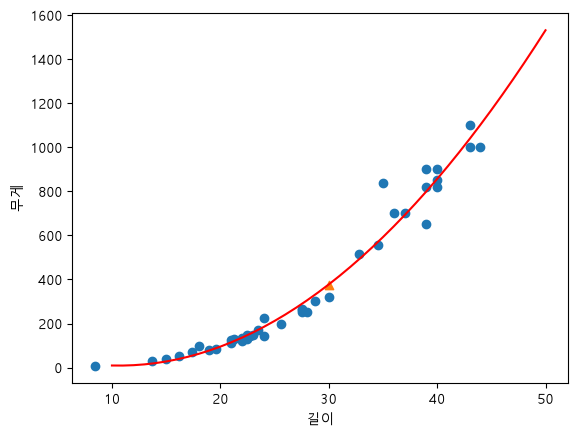

In [ ]:
# 산점그래프
plt.scatter(train_data,train_label)
plt.scatter(30,377, marker='^')
plt.plot(point,lr.coef_[0]*point**2+lr.coef_[1]*point+lr.intercept_,color='r')
plt.xlabel('길이')
plt.ylabel('무게')
plt.show()